In [9]:
import pandas as pd

In [10]:
df = pd.read_csv('matches_clean.csv')

In [11]:
df.shape

(1028, 18)

In [12]:
df.sample(105)

,id,season,city,date,match_type,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,year
405,733983,2014,Mumbai,2014-05-06,League,Wankhede Stadium,Mumbai Indians,Royal Challengers Bengaluru,Royal Challengers Bengaluru,field,Mumbai Indians,runs,19.0,188.0,20.0,N,Normal,2014
363,598043,2013,Kolkata,2013-05-03,League,Eden Gardens,Kolkata Knight Riders,Rajasthan Royals,Rajasthan Royals,bat,Kolkata Knight Riders,wickets,8.0,133.0,20.0,N,Normal,2013
813,1304050,2022,Mumbai,2022-03-28,League,Wankhede Stadium,Lucknow Super Giants,Gujarat Titans,Gujarat Titans,field,Gujarat Titans,wickets,5.0,159.0,20.0,N,Normal,2022
893,1359484,2023,Lucknow,2023-04-07,League,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,Sunrisers Hyderabad,Lucknow Super Giants,Sunrisers Hyderabad,bat,Lucknow Super Giants,wickets,5.0,122.0,20.0,N,Normal,2023
8,335990,2007,Hyderabad,2008-04-24,League,Rajiv Gandhi International Stadium,Sunrisers Hyderabad,Rajasthan Royals,Rajasthan Royals,field,Rajasthan Royals,wickets,3.0,215.0,20.0,N,Normal,2008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
448,829725,2015,Pune,2015-04-15,League,Maharashtra Cricket Association Stadium,Punjab Kings,Delhi Capitals,Punjab Kings,bat,Delhi Capitals,wickets,5.0,166.0,20.0,N,Normal,2015
427,734027,2014,Kolkata,2014-05-22,League,Eden Gardens,Kolkata Knight Riders,Royal Challengers Bengaluru,Royal Challengers Bengaluru,field,Kolkata Knight Riders,runs,30.0,196.0,20.0,N,Normal,2014
695,1178399,2019,Mumbai,2019-04-10,League,Wankhede Stadium,Punjab Kings,Mumbai Indians,Mumbai Indians,field,Mumbai Indians,wickets,3.0,198.0,20.0,N,Normal,2019
77,392203,2009,East London,2009-05-01,League,Buffalo Park,Kolkata Knight Riders,Mumbai Indians,Mumbai Indians,bat,Mumbai Indians,runs,9.0,149.0,20.0,N,Normal,2009


In [13]:
df.isnull().sum()

id               0
season           0
city             0
date             0
match_type       0
venue            0
team1            0
team2            0
toss_winner      0
toss_decision    0
winner           0
result           0
result_margin    0
target_runs      0
target_overs     0
super_over       0
method           0
year             0
dtype: int64

# Perform EDA operations

In [22]:
toss_win_pecentage = ((df['toss_winner'] == df['winner']).mean()) * 100
print(f"{toss_win_pecentage:.2f}%")

51.36%


## Data Visualization

In [23]:
import matplotlib as plt
import seaborn as sns

In [24]:
sns.set_style('whitegrid')

<Axes: ylabel='winner'>

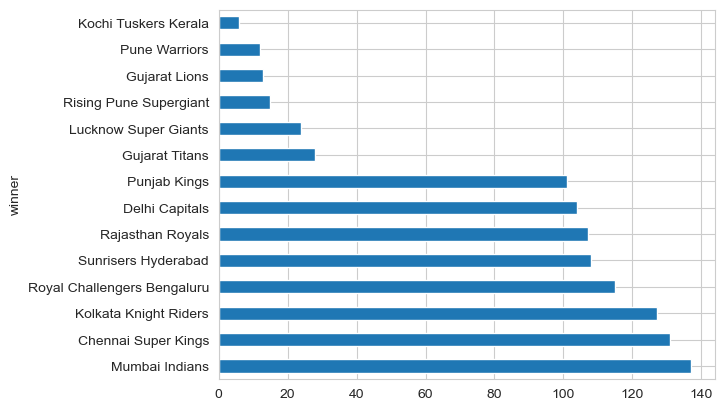

In [33]:
df['winner'].value_counts().plot(kind='barh')

<Axes: xlabel='toss_decision', ylabel='count'>

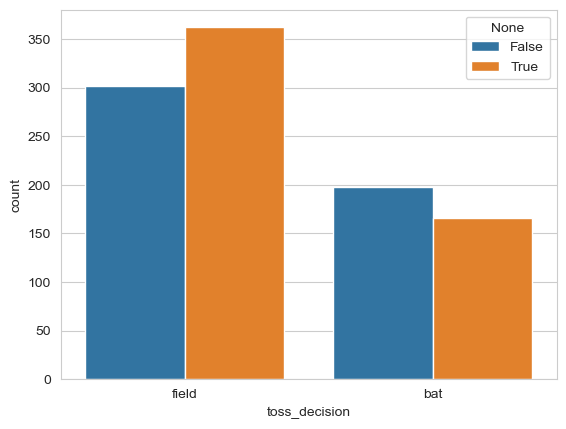

In [36]:
sns.countplot(data=df, x='toss_decision', hue=(df['toss_winner'] == df['winner']))

<Axes: ylabel='year'>

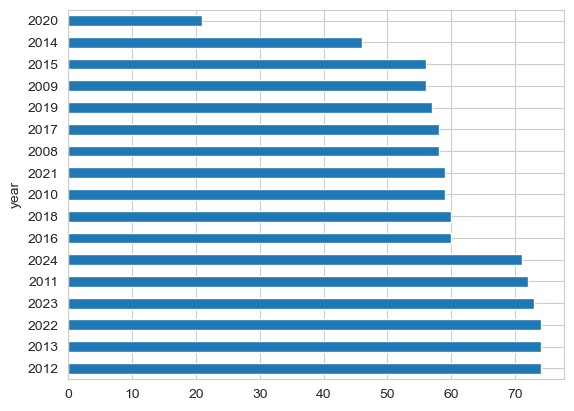

In [44]:
df['year'].value_counts().plot(kind='barh')

In [45]:
home_city = {
    'Mumbai Indians': 'Mumbai',
    'Chennai Super Kings': 'Chennai',
    'Kolkata Knight Riders': 'Kolkata',
    'Royal Challengers Bengaluru': 'Bengaluru',
    'Delhi Capitals': 'Delhi',
    'Rajasthan Royals': 'Jaipur',
    'Sunrisers Hyderabad': 'Hyderabad',
    'Punjab Kings': 'Chandigarh',
    'Lucknow Super Giants': 'Lucknow',
    'Gujarat Titans': 'Ahmedabad',
    'Rising Pune Supergiant': 'Pune',
    'Gujarat Lions': 'Rajkot',
    'Pune Warriors': 'Pune',
    'Kochi Tuskers Kerala': 'Kochi'
}

df['team1_home'] = (df['team1'].map(home_city) == df['city']).astype(int)
df['team2_home'] = (df['team2'].map(home_city) == df['city']).astype(int)

In [47]:
df.sample(2)

,id,season,city,date,match_type,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,year,team1_home,team2_home
220,501246,2011,Mumbai,2011-05-07,League,Wankhede Stadium,Mumbai Indians,Delhi Capitals,Delhi Capitals,field,Mumbai Indians,runs,32.0,179.0,20.0,N,Normal,2011,1,0
418,734009,2014,Cuttack,2014-05-14,League,Barabati Stadium,Kolkata Knight Riders,Mumbai Indians,Kolkata Knight Riders,field,Kolkata Knight Riders,wickets,6.0,142.0,20.0,N,Normal,2014,0,0


In [51]:
df['team1_won_toss'] = (df['team1'] == df['toss_winner']).astype(int)
df['team2_won_toss'] = (df['team2'] == df['toss_winner']).astype(int)

In [69]:
df.head(2)

,id,season,city,date,match_type,venue,team1,team2,toss_winner,toss_decision,...,result_margin,target_runs,target_overs,super_over,method,year,team1_home,team1_won_toss,match_win,choose_field
0,335982,2007,Bengaluru,2008-04-18,League,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,...,140.0,223.0,20.0,N,Normal,2008,1,1,0,1
1,335983,2007,Chandigarh,2008-04-19,League,Punjab Cricket Association IS Bindra Stadium,Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,...,33.0,241.0,20.0,N,Normal,2008,1,0,0,0


In [59]:
df['match_win'] = (df['team1'] == df['winner']).astype(int)

In [64]:
df['choose_field'] = (df['toss_decision'] == 'field').astype(int)

In [76]:
df.columns.tolist()

['id',
 'season',
 'city',
 'date',
 'match_type',
 'venue',
 'team1',
 'team2',
 'toss_winner',
 'toss_decision',
 'winner',
 'result',
 'result_margin',
 'target_runs',
 'target_overs',
 'super_over',
 'method',
 'year',
 'team1_home',
 'team1_won_toss',
 'choose_field',
 'team1_wins']

In [71]:
df['team1_wins'] = df['match_win']

In [75]:
df.head(2)

,id,season,city,date,match_type,venue,team1,team2,toss_winner,toss_decision,...,result_margin,target_runs,target_overs,super_over,method,year,team1_home,team1_won_toss,choose_field,team1_wins
0,335982,2007,Bengaluru,2008-04-18,League,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,...,140.0,223.0,20.0,N,Normal,2008,1,1,1,0
1,335983,2007,Chandigarh,2008-04-19,League,Punjab Cricket Association IS Bindra Stadium,Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,...,33.0,241.0,20.0,N,Normal,2008,1,0,0,0


In [74]:
df = df.drop(columns=['match_win'])

## Cossing Features and target columns

In [78]:
features = ['team1', 'team2', 'city', 'venue','team1_home', 'team1_won_toss', 'choose_field']

X = df[features]
y = df['team1_wins']

In [79]:
X

,team1,team2,city,venue,team1_home,team1_won_toss,choose_field
0,Royal Challengers Bengaluru,Kolkata Knight Riders,Bengaluru,M Chinnaswamy Stadium,1,1,1
1,Punjab Kings,Chennai Super Kings,Chandigarh,Punjab Cricket Association IS Bindra Stadium,1,0,0
2,Delhi Capitals,Rajasthan Royals,Delhi,Arun Jaitley Stadium,1,0,0
3,Mumbai Indians,Royal Challengers Bengaluru,Mumbai,Wankhede Stadium,1,1,0
4,Kolkata Knight Riders,Sunrisers Hyderabad,Kolkata,Eden Gardens,1,0,0
...,...,...,...,...,...,...,...
1023,Punjab Kings,Sunrisers Hyderabad,Hyderabad,Rajiv Gandhi International Stadium,0,1,0
1024,Sunrisers Hyderabad,Kolkata Knight Riders,Ahmedabad,Narendra Modi Stadium,0,1,0
1025,Royal Challengers Bengaluru,Rajasthan Royals,Ahmedabad,Narendra Modi Stadium,0,0,1
1026,Sunrisers Hyderabad,Rajasthan Royals,Chennai,MA Chidambaram Stadium,0,0,1


In [84]:
X = pd.get_dummies(X, columns=['team1', 'team2', 'city', 'venue'], drop_first=True).astype(int)

In [98]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [99]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((822, 97), (822,), (206, 97), (206,))

In [100]:
from sklearn.tree import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier()

In [101]:
dt_clf.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [102]:
y_pred = dt_clf.predict(x_test)

In [105]:
from sklearn.metrics import accuracy_score

round(accuracy_score(y_test, y_pred) * 100, 2)

45.63

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)
rf_clf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [107]:
rf_clf_pred = rf_clf.predict(x_test)

In [108]:
round(accuracy_score(y_test, rf_clf_pred) * 100, 2)

50.49

In [ ]:
rf_clf = RandomForestClassifier(
    n_estimators=800,
    max_depth=4,
    min_samples_leaf=4,
    random_state=42
)

In [124]:
rf_clf.fit(x_train, y_train)
rf_clf_pred = rf_clf.predict(x_test)
round(accuracy_score(y_test, rf_clf_pred) * 100, 2)

51.94

In [128]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=2000)
lr.fit(x_train, y_train)
print("LR test:", round(lr.score(x_test,y_test)*100,2), "%")

LR test: 51.46 %


In [129]:
df.sample(2)

,id,season,city,date,match_type,venue,team1,team2,toss_winner,toss_decision,...,result_margin,target_runs,target_overs,super_over,method,year,team1_home,team1_won_toss,choose_field,team1_wins
135,419127,2009,Chandigarh,2010-03-27,League,Punjab Cricket Association IS Bindra Stadium,Punjab Kings,Kolkata Knight Riders,Kolkata Knight Riders,bat,...,39.0,184.0,20.0,N,Normal,2010,1,0,0,0
120,419112,2009,Bengaluru,2010-03-16,League,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Punjab Kings,Punjab Kings,bat,...,8.0,204.0,20.0,N,Normal,2010,1,0,0,1
